# ICD 341 — Labs 9–13
**Mulungushi University · School of Natural and Applied Sciences · Dept. of Mathematics and Statistics**

Name: Frazer Musonda_202402902  

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

# Lab 1: Bootstrap & resampling

### Q1. Bootstrap the mean and a 95% percentile interval

In [2]:
data = np.array([3, 4, 5, 7, 8, 9])
n = len(data)
B = 10_000

# Each row is one bootstrap resample (sampling WITH replacement)
idx = rng.integers(0, n, size=(B, n))
boot_means = data[idx].mean(axis=1)

ci_mean = np.percentile(boot_means, [2.5, 97.5])
print(f"Sample mean          : {data.mean():.3f}")
print(f"Bootstrap mean       : {boot_means.mean():.3f}")
print(f"Bootstrap SE         : {boot_means.std(ddof=1):.3f}")
print(f"95% percentile CI    : ({ci_mean[0]:.3f}, {ci_mean[1]:.3f})")

Sample mean          : 6.000
Bootstrap mean       : 5.998
Bootstrap SE         : 0.880
95% percentile CI    : (4.333, 7.667)


### Q2. Bootstrap the median

In [3]:
boot_medians = np.median(data[idx], axis=1)   # reuse the same resamples

ci_median = np.percentile(boot_medians, [2.5, 97.5])
print(f"Sample median        : {np.median(data):.3f}")
print(f"Bootstrap SE         : {boot_medians.std(ddof=1):.3f}")
print(f"95% percentile CI    : ({ci_median[0]:.3f}, {ci_median[1]:.3f})")

Sample median        : 6.000
Bootstrap SE         : 1.376
95% percentile CI    : (3.500, 8.500)


The median's bootstrap distribution is lumpy (it can only take values that are, or are midpoints of, observed data points) and is usually wider/less smooth than the mean's with so few observations (n = 6).

### Q3. Parametric bootstrap from a fitted normal model

In [4]:
mu_hat = data.mean()
sigma_hat = data.std(ddof=1)
print(f"Fitted Normal(mu={mu_hat:.3f}, sigma={sigma_hat:.3f})")

# Simulate NEW datasets from the fitted model instead of resampling the data
sims = rng.normal(mu_hat, sigma_hat, size=(B, n))
pb_means = sims.mean(axis=1)
pb_medians = np.median(sims, axis=1)

print("Parametric bootstrap, mean   95% CI:", np.percentile(pb_means,   [2.5, 97.5]).round(3))
print("Parametric bootstrap, median 95% CI:", np.percentile(pb_medians, [2.5, 97.5]).round(3))

Fitted Normal(mu=6.000, sigma=2.366)
Parametric bootstrap, mean   95% CI: [4.095 7.827]
Parametric bootstrap, median 95% CI: [3.842 8.148]


### Q4. One way data leakage can occur during model validation

**Preprocessing before splitting.** If you standardise (or impute, or select features) using the *whole* dataset and only then split into train/validation, the validation rows have influenced the training pipeline: the scaler's mean and standard deviation already contain information about the validation data. The validation score is then optimistically biased and will not reflect performance on genuinely new data.

**Fix:** split first, fit every preprocessing step on the training fold only, then apply it to the validation fold (e.g. use a scikit-learn `Pipeline` inside `cross_val_score`).

# Lab 2: Bayesian MCMC

### Q1. Random-walk Metropolis–Hastings for a standard normal target

In [5]:
def rw_metropolis(log_target, n_samples, x0=0.0, step=1.0, seed=0):
    rng = np.random.default_rng(seed)
    x = x0
    logp = log_target(x)
    chain = np.empty(n_samples)
    accepted = 0
    for i in range(n_samples):
        proposal = x + step * rng.normal()          # symmetric proposal
        logp_prop = log_target(proposal)
        if np.log(rng.random()) < logp_prop - logp: # accept w.p. min(1, ratio)
            x, logp = proposal, logp_prop
            accepted += 1
        chain[i] = x
    return chain, accepted / n_samples

log_std_normal = lambda x: -0.5 * x**2             # unnormalised log N(0,1)

chain, acc = rw_metropolis(log_std_normal, 20_000, x0=5.0, step=2.4, seed=1)
burn = 2_000
post = chain[burn:]
print(f"Acceptance rate : {acc:.2f}")
print(f"Mean (target 0) : {post.mean():.3f}")
print(f"Std  (target 1) : {post.std():.3f}")

Acceptance rate : 0.44
Mean (target 0) : -0.030
Std  (target 1) : 0.984


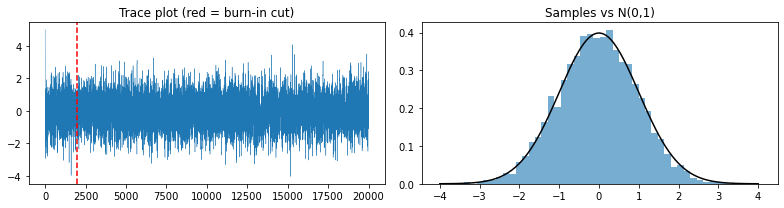

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(chain, lw=0.4); ax[0].axvline(burn, color="r", ls="--"); ax[0].set_title("Trace plot (red = burn-in cut)")
ax[1].hist(post, bins=50, density=True, alpha=0.6)
xs = np.linspace(-4, 4, 200); ax[1].plot(xs, stats.norm.pdf(xs), "k"); ax[1].set_title("Samples vs N(0,1)")
plt.tight_layout(); plt.show()

### Q2. Bernoulli probability, Beta(2,2) prior, 8 successes in 12 trials

In [7]:
a, b = 2, 2
k, n_trials = 8, 12

def log_post(theta):
    if theta <= 0 or theta >= 1:
        return -np.inf
    # log prior + log likelihood (up to a constant)
    return (a - 1 + k) * np.log(theta) + (b - 1 + n_trials - k) * np.log(1 - theta)

chain_b, acc_b = rw_metropolis(log_post, 30_000, x0=0.5, step=0.2, seed=2)
theta = chain_b[3_000:]

# Exact conjugate answer: Beta(a + k, b + n - k) = Beta(10, 6)
exact = stats.beta(a + k, b + n_trials - k)
print(f"Acceptance rate       : {acc_b:.2f}")
print(f"MCMC  posterior mean  : {theta.mean():.4f}   95% CI {np.percentile(theta, [2.5, 97.5]).round(3)}")
print(f"Exact posterior mean  : {exact.mean():.4f}   95% CI {exact.ppf([0.025, 0.975]).round(3)}")

Acceptance rate       : 0.56
MCMC  posterior mean  : 0.6254   95% CI [0.383 0.835]
Exact posterior mean  : 0.6250   95% CI [0.384 0.837]


The posterior is Beta(10, 6) with mean 10/16 = 0.625. It sits between the prior mean (0.5) and the sample proportion (8/12 ≈ 0.667): the Beta(2,2) prior acts like 4 pseudo-observations that pull the estimate slightly toward 0.5.

### Q3. Diagnostics

| Diagnostic | What it is | What you want to see |
|---|---|---|
| **Trace plot** | Sampled value versus iteration, one line per chain. | A "fuzzy caterpillar" that wanders around a stable level, with chains overlapping. Trends, drifts, or long flat stretches signal non-convergence or poor mixing. |
| **ACF** (autocorrelation function) | Correlation between the chain and itself lagged by *k* steps. | ACF dropping to ≈ 0 quickly. Slow decay means successive draws are highly dependent, so each draw carries little new information. |
| **R-hat** (Gelman–Rubin) | Compares between-chain variance with within-chain variance across several chains started from dispersed points. | Values ≈ 1.00 (commonly < 1.01). Values well above 1 mean chains disagree and have not converged to the same distribution. |
| **ESS** (effective sample size) | The number of *independent* draws that would give the same Monte Carlo precision, roughly N / (1 + 2·Σρₖ). | Large relative to N (a common rule of thumb is > 400 total, bulk and tail). A small ESS means strong autocorrelation and an imprecise estimate. |

### Q4. PyMC model for normally distributed observations

In [12]:
# Requires: pip install pymc arviz
import pymc as pm
import arviz as az

# Simulated observations (replace with real data)
y_obs = np.random.default_rng(0).normal(loc=5.0, scale=2.0, size=100)

with pm.Model() as normal_model:
    mu    = pm.Normal("mu", mu=0, sigma=10)           # weakly informative prior on the mean
    sigma = pm.HalfNormal("sigma", sigma=5)           # positive prior on the std dev
    y     = pm.Normal("y", mu=mu, sigma=sigma, observed=y_obs)

    idata = pm.sample(draws=1000, tune=1000, chains=4, random_seed=42)

print(az.summary(idata, var_names=["mu", "sigma"]))   # check r_hat and ess_bulk here
az.plot_trace(idata, var_names=["mu", "sigma"]);

ModuleNotFoundError: No module named 'pymc'

# Lab 3: Advanced simulation

### Q1. 5,000 exponential samples by inverse transform (rate 3)

In [9]:
lam = 3.0
u = rng.random(5_000)
# CDF: F(x) = 1 - exp(-lam x)  =>  F^{-1}(u) = -ln(1 - u) / lam
exp_samples = -np.log(1 - u) / lam

print(f"Sample mean (theory 1/3 = {1/lam:.4f}): {exp_samples.mean():.4f}")
print(f"Sample var  (theory 1/9 = {1/lam**2:.4f}): {exp_samples.var():.4f}")
print("KS test vs Exp(3):", stats.kstest(exp_samples, "expon", args=(0, 1/lam)))

Sample mean (theory 1/3 = 0.3333): 0.3311
Sample var  (theory 1/9 = 0.1111): 0.1071
KS test vs Exp(3): KstestResult(statistic=0.009752389223131819, pvalue=0.7246109794414517)


### Q2. Sampling from a categorical distribution, p = [0.1, 0.6, 0.3]

In [10]:
p = np.array([0.1, 0.6, 0.3])
cum = np.cumsum(p)                                   # [0.1, 0.7, 1.0]
N = 10_000

# Inverse-CDF method: find which cumulative bin each uniform falls in
cat_samples = np.searchsorted(cum, rng.random(N), side="right")
freq = np.bincount(cat_samples, minlength=3) / N
print("Empirical frequencies:", freq.round(3), " target:", p)

# Built-in equivalent
print("rng.choice          :", (np.bincount(rng.choice(3, size=N, p=p), minlength=3) / N).round(3))

Empirical frequencies: [0.095 0.599 0.306]  target: [0.1 0.6 0.3]
rng.choice          : [0.099 0.604 0.298]


### Q3. Rejection sampling for Beta(2,2)

In [11]:
# Target f(x) = 6 x (1 - x) on [0, 1]; maximum is 1.5 at x = 0.5.
# Proposal g = Uniform(0,1) (density 1), envelope constant M = 1.5.
f = lambda x: 6 * x * (1 - x)
M = 1.5

def rejection_beta22(n, rng):
    out = []
    tries = 0
    while len(out) < n:
        x = rng.random(n)                  # proposals
        u = rng.random(n)
        keep = u <= f(x) / (M * 1.0)       # accept w.p. f(x) / (M g(x))
        out.extend(x[keep])
        tries += n
    return np.array(out[:n]), n / tries

rs, _ = rejection_beta22(10_000, rng)
print(f"Mean (theory 0.5)   : {rs.mean():.4f}")
print(f"Var  (theory 0.05)  : {rs.var():.4f}")
print(f"Theoretical acceptance rate = 1/M = {1/M:.3f}")
print("KS test vs Beta(2,2):", stats.kstest(rs, "beta", args=(2, 2)))

Mean (theory 0.5)   : 0.5004
Var  (theory 0.05)  : 0.0500
Theoretical acceptance rate = 1/M = 0.667
KS test vs Beta(2,2): KstestResult(statistic=0.00591255779400246, pvalue=0.8735269305417235)


### Q4. The four main particle-filter steps

1. **Initialise:** draw N particles {xₜ⁽ⁱ⁾} from the prior on the initial state and give each weight 1/N.
2. **Predict (propagate):** move every particle forward through the state-transition model, xₜ⁽ⁱ⁾ ~ p(xₜ | xₜ₋₁⁽ⁱ⁾), including process noise.
3. **Update (weight):** when the observation yₜ arrives, set each weight proportional to its likelihood, wₜ⁽ⁱ⁾ ∝ wₜ₋₁⁽ⁱ⁾ · p(yₜ | xₜ⁽ⁱ⁾), then normalise the weights to sum to 1. The weighted particles approximate the filtering distribution p(xₜ | y₁:ₜ).
4. **Resample:** draw N particles with replacement in proportion to the weights (typically when the effective sample size 1/Σwᵢ² falls below a threshold) and reset the weights to 1/N. This removes particles with negligible weight and duplicates promising ones, which prevents weight degeneracy.

Repeat steps 2–4 for each new observation.

### Q5. What a non-uniform SBC rank histogram may indicate

Simulation-based calibration draws a parameter from the prior, simulates data, fits the model, and records the rank of the true parameter among the posterior draws. If the model, the sampler, and the generating process are all consistent, the ranks are **uniform**. Departures suggest a problem:

- **U-shaped** (too many extreme ranks): the posterior is **over-confident**, i.e. too narrow, so the true value often falls outside the bulk of the draws.
- **Hump-shaped / inverted-U**: the posterior is **under-confident**, i.e. too wide.
- **Sloped / skewed** (excess low or high ranks): the posterior is **biased**, consistently over- or under-estimating the parameter.
- **Spikes at the edges or in specific bins**: often a sign of strong autocorrelation (poor MCMC mixing / low ESS) or discretisation of ranks.

Common causes: a bug in the model or the data-generating code, a mismatch between the simulator and the fitted model, a prior used for simulation that differs from the prior in the fit, or a sampler that has not converged.

# Lab 4: Testing, estimators, packaging

### Q1. Median function with tests (known result and empty input)

In [ ]:
import numpy as np

def median(values):
    """Return the median of a 1-D iterable of numbers. Raises ValueError if empty."""
    arr = np.sort(np.asarray(values, dtype=float))
    n = arr.size
    if n == 0:
        raise ValueError("median() of an empty input is undefined")
    mid = n // 2
    return float(arr[mid]) if n % 2 else float((arr[mid - 1] + arr[mid]) / 2)

# --- tests (pytest would collect any function named test_*) ---
def test_median_known_odd():
    assert median([3, 1, 2]) == 2.0

def test_median_known_even():
    assert median([1, 2, 3, 4]) == 2.5

def test_median_matches_numpy():
    x = np.random.default_rng(0).normal(size=101)
    assert np.isclose(median(x), np.median(x))

def test_median_empty_raises():
    try:
        median([])
    except ValueError:
        return
    raise AssertionError("expected ValueError for empty input")

for t in (test_median_known_odd, test_median_known_even, test_median_matches_numpy, test_median_empty_raises):
    t(); print("PASS", t.__name__)

With pytest installed, save the functions in `test_median.py` and run `pytest`; for the empty case you can write `with pytest.raises(ValueError): median([])`.

### Q2. Tests that a probability estimate lies in [0, 1]

In [ ]:
def estimate_probability(successes, trials):
    """Posterior-mean estimate with a Beta(1,1) prior (Laplace smoothing)."""
    if trials <= 0 or not (0 <= successes <= trials):
        raise ValueError("need trials > 0 and 0 <= successes <= trials")
    return (successes + 1) / (trials + 2)

def test_probability_in_unit_interval():
    for n in range(1, 101):
        for k in range(n + 1):                      # includes the edge cases k=0 and k=n
            p = estimate_probability(k, n)
            assert 0.0 <= p <= 1.0, (k, n, p)

def test_probability_invalid_inputs_raise():
    for bad in [(1, 0), (-1, 5), (6, 5)]:
        try:
            estimate_probability(*bad)
        except ValueError:
            continue
        raise AssertionError(f"expected ValueError for {bad}")

test_probability_in_unit_interval();       print("PASS test_probability_in_unit_interval")
test_probability_invalid_inputs_raise();   print("PASS test_probability_invalid_inputs_raise")

### Q3. Transformer that scales each column by its standard deviation

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class StdScaler(BaseEstimator, TransformerMixin):
    """Divide each column by its standard deviation (no centering)."""

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        scale = X.std(axis=0, ddof=0)
        scale[scale == 0] = 1.0            # avoid division by zero for constant columns
        self.scale_ = scale
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, "scale_")
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("X has a different number of columns than during fit")
        return X / self.scale_

X = np.random.default_rng(1).normal(loc=[0, 5, -3], scale=[1, 10, 0.1], size=(500, 3))
Xs = StdScaler().fit_transform(X)
print("Column std after scaling:", Xs.std(axis=0).round(3))     # -> [1. 1. 1.]

### Q4. Minimal `pyproject.toml` and editable installation

Project layout:
```
labtools/
├── pyproject.toml
└── labtools/
    ├── __init__.py        # e.g. from .scaler import StdScaler
    └── scaler.py
```

`pyproject.toml`:
```toml
[build-system]
requires = ["setuptools>=61"]
build-backend = "setuptools.build_meta"

[project]
name = "labtools"
version = "0.1.0"
description = "Small statistical-computing helpers"
requires-python = ">=3.9"
dependencies = ["numpy", "scikit-learn"]

[tool.setuptools]
packages = ["labtools"]
```

**Editable installation** (`pip install -e .` from the folder containing `pyproject.toml`): instead of copying the package into `site-packages`, pip installs the project's metadata and a small link/import hook (PEP 660) that makes Python import `labtools` **directly from your source folder**. Edits to the `.py` files take effect immediately without reinstalling, so you can develop and run tests against the real, importable package. You only need to reinstall if you change metadata such as dependencies or entry points. A normal `pip install .` instead takes a snapshot copy, so later source edits are not seen.

# Lab 5: Performance and scalability

### Q1. Vectorise x² + 2x + 1 for one million values

In [ ]:
x = np.random.default_rng(0).random(1_000_000)

def poly_loop(x):
    out = np.empty_like(x)
    for i in range(x.size):
        out[i] = x[i]**2 + 2*x[i] + 1
    return out

t0 = time.perf_counter(); y_loop = poly_loop(x);           t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_vec  = x**2 + 2*x + 1;         t_vec  = time.perf_counter() - t0

print(f"Python loop : {t_loop:.4f} s")
print(f"Vectorised  : {t_vec:.4f} s   (~{t_loop / t_vec:.0f}x faster)")
print("Results equal:", np.allclose(y_loop, y_vec))

### Q2. Numba function that sums the squares

In [ ]:
# Requires: pip install numba
from numba import njit

@njit
def sum_squares(a):
    total = 0.0
    for i in range(a.size):
        total += a[i] * a[i]
    return total

sum_squares(x[:10])                       # warm-up call: triggers JIT compilation

t0 = time.perf_counter(); s_numba = sum_squares(x); t_numba = time.perf_counter() - t0
t0 = time.perf_counter(); s_numpy = np.sum(x**2);   t_numpy = time.perf_counter() - t0
print(f"Numba {s_numba:.4f} ({t_numba:.5f} s)  |  NumPy {s_numpy:.4f} ({t_numpy:.5f} s)")

### Q3. Parallel bootstrap of a sample mean with joblib

In [ ]:
from joblib import Parallel, delayed

sample = np.random.default_rng(3).normal(50, 10, size=2_000)

def boot_chunk(data, n_boot, seed):
    """Return n_boot bootstrap means using an independent RNG stream."""
    r = np.random.default_rng(seed)
    idx = r.integers(0, data.size, size=(n_boot, data.size))
    return data[idx].mean(axis=1)

n_jobs, per_job = 4, 2_500                                    # 10,000 resamples in total
seeds = np.random.SeedSequence(123).spawn(n_jobs)             # independent, reproducible streams

t0 = time.perf_counter()
chunks = Parallel(n_jobs=n_jobs)(delayed(boot_chunk)(sample, per_job, s) for s in seeds)
t_par = time.perf_counter() - t0

boot = np.concatenate(chunks)
print(f"{boot.size} bootstrap means in {t_par:.2f} s")
print(f"Mean of means : {boot.mean():.3f}  (sample mean {sample.mean():.3f})")
print(f"95% CI        : {np.percentile(boot, [2.5, 97.5]).round(3)}")

### Q4. Dask Array: mean of a large chunked array

In [ ]:
# Requires: pip install "dask[array]"
import dask.array as da

big = da.random.random((20_000, 5_000), chunks=(2_000, 5_000))   # 100M values, lazily split into 10 chunks
print(big)                                                       # nothing computed yet (lazy task graph)

result = big.mean()          # builds a graph: per-chunk partial sums/counts, then a combine step
print("Mean (expect ~0.5):", result.compute())    # executes chunks in parallel without loading all into RAM at once

### Q5. Why benchmark timing should exclude Numba's first call

Numba is a **just-in-time** compiler: the first call with a given argument type signature compiles the Python function to machine code, which can take hundreds of milliseconds to seconds. That one-off compile cost is not part of the function's steady-state runtime, and the compiled code is cached for later calls with the same types. If the first call is included, the measurement mostly reflects compilation overhead and can make a fast function look slower than plain NumPy. Good practice is to **warm up** (call once on small input of the same dtype), then time several subsequent calls (e.g. with `timeit` / best of *n*). Report compilation time separately if it matters, for example for short-lived scripts that call the function only once.